In [2]:
from google.colab import drive
import os


drive.mount('/content/drive')


BASE_PATH = '/content/drive/MyDrive/Breederify'
DATASET_PATH = os.path.join(BASE_PATH, 'dataset')
MODEL_SAVE_PATH = os.path.join(BASE_PATH, 'breederify_siamese_model.keras')

Mounted at /content/drive


Import Libraries

In [3]:
import cv2
import numpy as np
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve
from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [5]:
def load_and_split_data(dataset_path, train_ratio=0.8):
    train_images_by_class = []
    val_images_by_class = []

    class_names = os.listdir(dataset_path)
    print(f"Found Classes: {class_names}")

    for breed in class_names:
        breed_path = os.path.join(dataset_path, breed)
        if not os.path.isdir(breed_path):
            continue

        raw_breed_imgs = []


        for img_name in os.listdir(breed_path):
            img_path = os.path.join(breed_path, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (224, 224))
                img = img.astype('float32') / 255.0
                raw_breed_imgs.append(img)


        train_imgs, val_imgs = train_test_split(raw_breed_imgs, train_size=train_ratio, random_state=42)



        augmented_train_imgs = []
        for img in train_imgs:
            augmented_train_imgs.append(img)
            augmented_train_imgs.append(cv2.flip(img, 1))

        train_images_by_class.append(augmented_train_imgs)
        val_images_by_class.append(val_imgs)

        print(f"{breed}: {len(augmented_train_imgs)} Train images (Augmented), {len(val_imgs)} Val images (Raw)")

    return train_images_by_class, val_images_by_class


def create_pairs(img_by_class):
    pairs = []
    labels = []
    class_num = len(img_by_class)

    for i in range(class_num):
        num_img = len(img_by_class[i])
        for j in range(num_img):
            for k in range(j + 1, num_img):

                img1 = img_by_class[i][j]
                img2 = img_by_class[i][k]
                pairs.append([img1, img2])
                labels.append(1.0)


                negative = random.choice([idx for idx in range(class_num) if idx != i])


                if len(img_by_class[negative]) > 0:
                    img3 = random.choice(img_by_class[negative])
                    pairs.append([img1, img3])
                    labels.append(0.0)

    return np.array(pairs), np.array(labels)


print("--- Loading and Splitting Data ---")
train_data, val_data = load_and_split_data(DATASET_PATH)

print("\n--- Generating Training Pairs ---")
train_pairs, train_labels = create_pairs(train_data)
print(f"Total Train Pairs: {len(train_pairs)}")

print("\n--- Generating Validation Pairs ---")
val_pairs, val_labels = create_pairs(val_data)
print(f"Total Validation Pairs: {len(val_pairs)}")

--- Loading and Splitting Data ---
Found Classes: ['Dachshund', 'toy_poodle', 'Half_labrador', 'Labrador']
Dachshund: 16 Train images (Augmented), 2 Val images (Raw)
toy_poodle: 16 Train images (Augmented), 2 Val images (Raw)
Half_labrador: 16 Train images (Augmented), 2 Val images (Raw)
Labrador: 16 Train images (Augmented), 2 Val images (Raw)

--- Generating Training Pairs ---
Total Train Pairs: 960

--- Generating Validation Pairs ---
Total Validation Pairs: 8


In [6]:

class EuclideanDistanceLayer(layers.Layer):
    def call(self, inputs):
        x, y = inputs
        sum_square = tf.math.reduce_sum(tf.math.square(x - y), axis=1, keepdims=True)
        return tf.math.sqrt(tf.math.maximum(sum_square, 1e-7))


def contrastive_loss(y_true, y_pred):
    margin = 1.0
    y_true = tf.cast(y_true, tf.float32)
    square_pred = tf.math.square(y_pred)
    margin_square = tf.math.square(tf.math.maximum(margin - y_pred, 0))
    return tf.math.reduce_mean(y_true * square_pred + (1 - y_true) * margin_square)

def build_siamese_model():

    base_cnn = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))


    base_cnn.trainable = True
    for layer in base_cnn.layers[:-20]:
        layer.trainable = False




    inputs = layers.Input(shape=(224, 224, 3))
    x = base_cnn(inputs)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation=None)(x)
    embeddings = layers.UnitNormalization()(x)

    embedding_network = Model(inputs, embeddings)


    input_1 = layers.Input(shape=(224, 224, 3), name="left_image")
    input_2 = layers.Input(shape=(224, 224, 3), name="right_image")

    emb_1 = embedding_network(input_1)
    emb_2 = embedding_network(input_2)


    distance = EuclideanDistanceLayer()([emb_1, emb_2])

    siamese_model = Model(inputs=[input_1, input_2], outputs=distance)
    return siamese_model


print("Building and compiling model...")
model = build_siamese_model()
model.compile(loss=contrastive_loss, optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001))

print("Starting Fine-Tuning Phase...")




train_img_1 = train_pairs[:, 0]
train_img_2 = train_pairs[:, 1]

val_img_1 = val_pairs[:, 0]
val_img_2 = val_pairs[:, 1]


history = model.fit(
    x=[train_img_1, train_img_2],
    y=train_labels,
    batch_size=8,
    epochs=15,
    validation_data=([val_img_1, val_img_2], val_labels)
)

model.save(MODEL_SAVE_PATH)
print(f"Training complete! Model saved to Google Drive: {MODEL_SAVE_PATH}")

Building and compiling model...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Starting Fine-Tuning Phase...
Epoch 1/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 46s 95ms/step - loss: 0.0694 - val_loss: 0.0158
Epoch 2/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0091 - val_loss: 0.0149
Epoch 3/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0049 - val_loss: 0.0168
Epoch 4/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0032 - val_loss: 0.0162
Epoch 5/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0023 - val_loss: 0.0178
Epoch 6/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0020 - val_loss: 0.0212
Epoch 7/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0016 - val_loss: 0.0173
Epoch 8/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: 0.0013 - val_loss: 0.0171
Epoch 9/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0011 - val_loss: 0.0144
Epoch 10/15
120/120 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 9.9978e-04 - val_loss: 0.0147
Epoch 11/15
1

In [24]:
val_img_1 = val_pairs[:, 0]
val_img_2 = val_pairs[:, 1]


distances = model.predict([val_img_1, val_img_2])


THRESHOLD = 0.2
predictions = (distances < THRESHOLD).astype(float)


tn, fp, fn, tp = confusion_matrix(val_labels, predictions).ravel()
accuracy = (tp + tn) / (tp + tn + fp + fn)

print(f"\n--- RESULTS WITH THRESHOLD {THRESHOLD} ---")
print(f"True Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(f"Correctly identified different breeds (True Negatives):  {tn}")
print(f"Mistakenly thought same breed (False Positives):         {fp}")
print(f"Mistakenly thought different breeds (False Negatives):   {fn}")
print(f"Correctly identified same breed (True Positives):        {tp}")


fpr, tpr, roc_thresholds = roc_curve(val_labels, -distances)
eer = brentq(lambda x : 1. - x - interp1d(fpr, tpr)(x), 0., 1.)

print("\n--- ADVANCED METRICS ---")
print(f"Equal Error Rate (EER): {eer * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step

--- RESULTS WITH THRESHOLD 0.2 ---
True Accuracy: 100.00%

Confusion Matrix:
Correctly identified different breeds (True Negatives):  4
Mistakenly thought same breed (False Positives):         0
Mistakenly thought different breeds (False Negatives):   0
Correctly identified same breed (True Positives):        4

--- ADVANCED METRICS ---
Equal Error Rate (EER): 0.00%


Loading Breederify Model...

Loading unknown query image...
Scanning through the dataset folders...
Checked against Dachshund folder: Average Distance = 0.5501
Checked against toy_poodle folder: Average Distance = 0.8200
Checked against Half_labrador folder: Average Distance = 0.6380
Checked against Labrador folder: Average Distance = 0.6999

===================================BREEDERIFY SEARCH RESULT


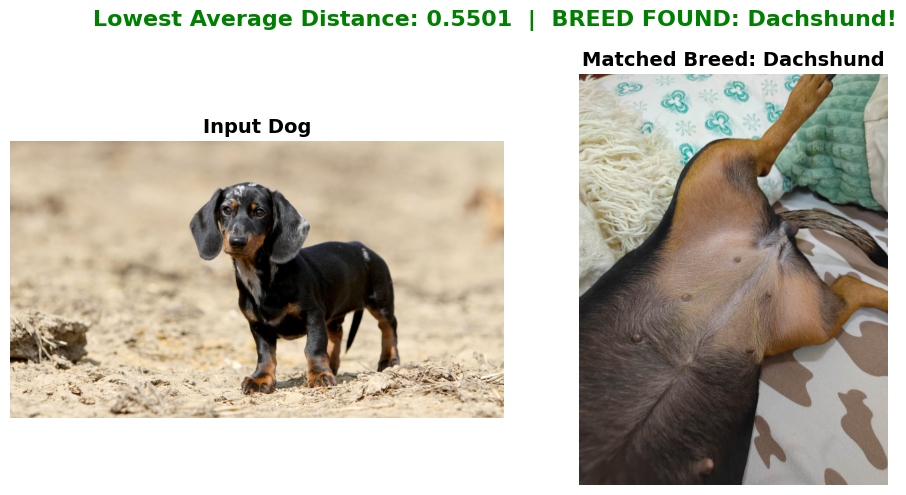

In [ ]:
class EuclideanDistanceLayer(layers.Layer):
    def call(self, inputs):
        x, y = inputs
        sum_square = tf.math.reduce_sum(tf.math.square(x - y), axis=1, keepdims=True)
        return tf.math.sqrt(tf.math.maximum(sum_square, 1e-7))

def contrastive_loss(y_true, y_pred):
    margin = 1.0
    y_true = tf.cast(y_true, tf.float32)
    square_pred = tf.math.square(y_pred)
    margin_square = tf.math.square(tf.math.maximum(margin - y_pred, 0))
    return tf.math.reduce_mean(y_true * square_pred + (1 - y_true) * margin_square)


MODEL_SAVE_PATH = os.path.join(BASE_PATH, 'breederify_siamese_model.keras')
custom_objects = {
    'EuclideanDistanceLayer': EuclideanDistanceLayer,
    'contrastive_loss': contrastive_loss
}
print("Loading Breederify Model...")
loaded_model = tf.keras.models.load_model(MODEL_SAVE_PATH, custom_objects=custom_objects, safe_mode=False)

def prepare_and_load_image(img_path):
    img = cv2.imread(img_path)
    if img is None:
        raise ValueError(f"Could not load image at {img_path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (224, 224))
    img_normalized = img_resized.astype('float32') / 255.0
    img_tensor = np.expand_dims(img_normalized, axis=0)
    return img_rgb, img_tensor

QUERY_IMG_PATH = os.path.join(BASE_PATH, 'unknown_dog.jpg')

DATASET_DIR = os.path.join(BASE_PATH, 'dataset')

THRESHOLD = 0.8

try:
    print("\nLoading unknown query image...")
    query_display, query_tensor = prepare_and_load_image(QUERY_IMG_PATH)

    best_match_name = "No breed found"
    best_match_distance = float('inf')
    best_match_display = None

    print(f"Scanning through the dataset folders...")

    class_names = [d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))]

    for breed in class_names:
        breed_path = os.path.join(DATASET_DIR, breed)
        breed_distances = []
        first_ref_display = None

        for img_name in os.listdir(breed_path):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                ref_path = os.path.join(breed_path, img_name)
                ref_display, ref_tensor = prepare_and_load_image(ref_path)

                if first_ref_display is None:
                    first_ref_display = ref_display

                distance = loaded_model.predict([query_tensor, ref_tensor], verbose=0)[0][0]
                breed_distances.append(distance)

        if len(breed_distances) > 0:
            avg_distance = np.mean(breed_distances)
            print(f"Checked against {breed} folder: Average Distance = {avg_distance:.4f}")

            if avg_distance < best_match_distance:
                best_match_distance = avg_distance
                best_match_name = breed
                best_match_display = first_ref_display

    print("\n===================================BREEDERIFY SEARCH RESULT")

    if best_match_distance < THRESHOLD:
        result_text = f"BREED FOUND: {best_match_name}!"
        text_color = "green"

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(query_display)
        axes[0].set_title("Input Dog", fontsize=14, fontweight='bold')
        axes[0].axis('off')

        axes[1].imshow(best_match_display)
        axes[1].set_title(f"Matched Breed: {best_match_name}", fontsize=14, fontweight='bold')
        axes[1].axis('off')

    else:
        result_text = "NO BREED FOUND IN DATABASE."
        text_color = "red"

        fig, axes = plt.subplots(1, 1, figsize=(5, 5))
        axes.imshow(query_display)
        axes.set_title("Input Dog", fontsize=14, fontweight='bold')
        axes.axis('off')

    plt.suptitle(f"Lowest Average Distance: {best_match_distance:.4f}  |  {result_text}",
                 fontsize=16, color=text_color, fontweight='bold')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error: {e}")